# QMI Portfolio Project: Starter Notebook
**Due Wednesday, Nov 11.** Present 10-15 min. Bring this notebook and `my_strategy.py`.

**Task:** write `get_weights(history)` that splits $1 across stocks for the **lowest realized volatility after trading costs**, on data you have not seen.

**Rules**
- `history` = DataFrame of daily simple returns, every row strictly before the rebalance date. Return a NumPy array, one weight per column, summing to 1.
- Rebalance every 21 trading days, 10 bp cost per dollar traded.
- Max 25% per position (absolute value), gross exposure (sum of |w|) at most 1.5.
- Must work for any number of stocks. Use only `history` and standard libraries (no files, no network).
- AI is allowed. 70% of your grade is defending every choice live. If you cannot explain a line, it is not yours.

**Files in the same folder:** `qmi_harness.py` (do not edit), `sp500_20_stocks_1990_2019.csv`, `messy_20_stocks_1989_2018.csv`.

In [5]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from qmi_harness import evaluate, summarize, make_strategy, min_var_weights, port_vol, LECTURE_SOLUTION
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 1. Load the clean data and look at it

In [6]:
prices = pd.read_csv("sp500_20_stocks_1990_2019.csv", index_col=0, parse_dates=True)
assert prices.index.is_monotonic_increasing and prices.index.is_unique
assert not prices.isna().any().any() and (prices > 0).all().all()
rets = prices.pct_change().dropna()      # simple daily returns
print(rets.shape, rets.index.min().date(), "to", rets.index.max().date())
rets.describe().T.head()

(7558, 20) 1990-01-03 to 2019-12-31


,count,mean,std,min,25%,50%,75%,max
AAPL,"7,558.000",0.001,0.028,-0.518,-0.012,0.000,0.014,0.333
AMD,"7,558.000",0.001,0.039,-0.379,-0.019,0.000,0.020,0.523
BAC,"7,558.000",0.001,0.026,-0.290,-0.010,0.000,0.011,0.353
BBY,"7,558.000",0.001,0.032,-0.388,-0.013,0.000,0.015,0.232
CVX,"7,558.000",0.001,0.015,-0.125,-0.008,0.000,0.009,0.209


## 2. Your strategy (start here)
Equal weight is the baseline to beat. Replace the body with your rule.

In [7]:
def make_top10_strategy():
    held = []
    start = None
    last_quarter = None

    def get_weights(history: pd.DataFrame) -> np.ndarray:
        nonlocal held, start, last_quarter

        if len(history) < 126:
            raise ValueError("Need at least 6 months of history.")

        if start is None:
            start = len(history)

        # Approximate 3 months as 63 trading days.
        quarter = (len(history) - start) // 63

        if last_quarter is None or quarter > last_quarter:
            previous = history.iloc[-126:-63]
            recent = history.iloc[-63:]

            def sharpe(data):
                volatility = data.std().replace(0, np.nan)
                score = data.mean() / volatility
                return score.where(data.count() >= 50)

            improvement = sharpe(recent) - sharpe(previous)
            improvement = improvement.replace(
                [np.inf, -np.inf], np.nan
            ).dropna()

            if len(improvement) < 10:
                raise ValueError("Need 10 eligible stocks.")

            # Full selection initially and every 9 months.
            full_refresh = (
                last_quarter is None
                or quarter // 3 > last_quarter // 3
            )

            if full_refresh:
                held = improvement.nlargest(10).index.tolist()
            else:
                # Protect the strongest 5 existing holdings.
                existing = improvement.reindex(held).dropna()
                keep = existing.nlargest(5).index.tolist()

                # Other slots remain open to all other stocks.
                candidates = improvement.drop(index=keep)
                fill = candidates.nlargest(
                    10 - len(keep)
                ).index.tolist()

                held = keep + fill

            last_quarter = quarter

        weights = pd.Series(0.0, index=history.columns)
        weights.loc[held] = 0.10
        return weights.to_numpy()

    return get_weights

## 3. Test it honestly
Development window 2000-2019. Tune on **2000-2009**, check on **2010-2019**, and do not keep re-tuning on the check window.

In [9]:
results = {
    "Equal weight": evaluate(make_strategy("ew"), rets, "2010-01-01", "2019-12-31"),
    "Lecture solution": evaluate(LECTURE_SOLUTION, rets, "2010-01-01", "2019-12-31"),
    "My rule": evaluate(make_top10_strategy(), rets, "2010-01-01", "2019-12-31"),
}
summarize(results)

,vol,promised_vol,vol_ratio,ann_ret,sharpe,max_dd,turnover,avg_max_weight,avg_gross,violation_share
Equal weight,0.146,0.147,0.994,0.144,0.995,-0.197,0.044,0.050,1.000,0.000
Lecture solution,0.112,0.106,1.052,0.136,1.197,-0.139,0.155,0.189,1.000,0.000
My rule,0.154,0.159,0.972,0.180,1.149,-0.179,0.393,0.100,1.000,0.000


In [10]:
table = summarize(results)

display(
    table[
        ["ann_ret", "vol", "sharpe", "max_dd", "turnover", "violation_share"]
    ].style.format({
        "ann_ret": "{:.2%}",
        "vol": "{:.2%}",
        "sharpe": "{:.2f}",
        "max_dd": "{:.2%}",
        "turnover": "{:.2%}",
        "violation_share": "{:.2%}",
    })
)

,ann_ret,vol,sharpe,max_dd,turnover,violation_share
Equal weight,14.42%,14.61%,1.00,-19.72%,4.37%,0.00%
Lecture solution,13.63%,11.20%,1.20,-13.94%,15.50%,0.00%
My rule,17.96%,15.41%,1.15,-17.89%,39.31%,0.00%


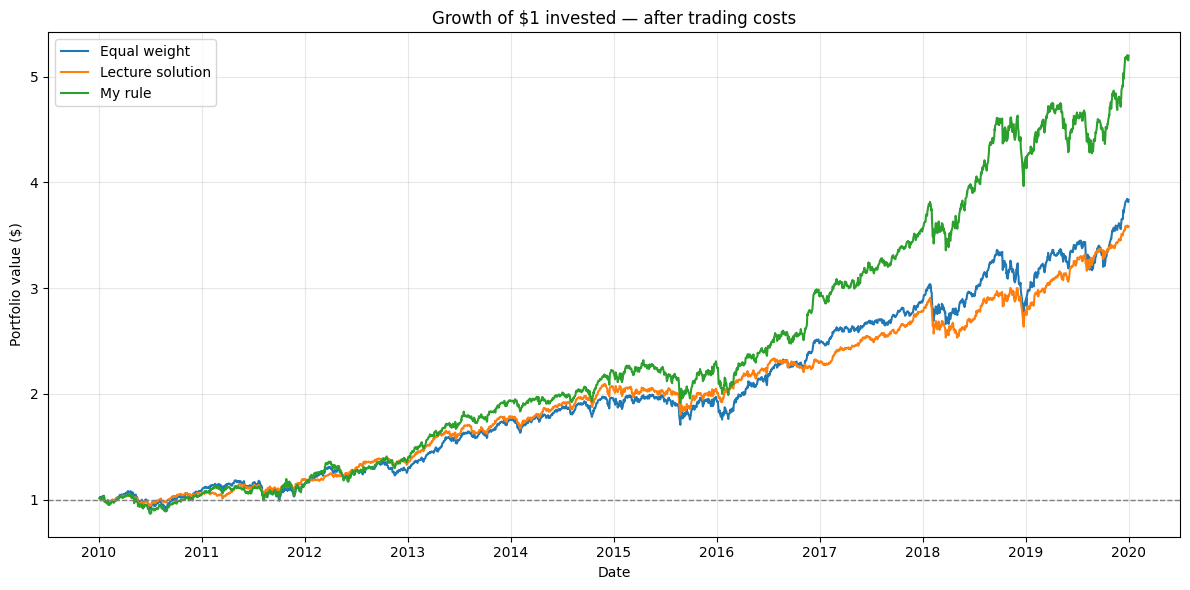

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))

for name, result in results.items():
    growth = (1 + result["returns"]).cumprod()
    ax.plot(growth.index, growth, label=name)

ax.set_title("Growth of $1 invested — after trading costs")
ax.set_xlabel("Date")
ax.set_ylabel("Portfolio value ($)")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

How to read it: `vol` = risk you actually delivered. `vol_ratio` = delivered / promised (near 1 = honest). `turnover` = trading per rebalance. `violation_share` must be 0.

## Tier 1: Replicate on the messy data
Load `messy_20_stocks_1989_2018.csv`. Some stocks start late (leading gaps). Decide how to handle it, justify it, then report the same comparison table.

In [ ]:
# your code here

## Tier 2: Change ONE major thing and prove it helped
Ideas: exponentially weighted covariance, one-factor model, different shrinkage target, risk parity, turnover penalty, window chosen from data. Show before/after numbers.

In [ ]:
# your code here

## Tier 3 (optional): Stress test
What happens in 2008 and 2020? Change something because of what you find.

In [ ]:
# your code here

## Prepare to answer (each teammate)
- Why that window, cap, or estimator? What did you try that did not work?
- What stops your function from seeing the future?
- What did your change cost, and what did it buy?
- What result would make you distrust your own solution?

Finally, copy your `get_weights` into `my_strategy.py` (with its imports) and test that it runs on its own.